# 05 — `sympy` / `sympy.stats` (Probabilitas Simbolik & Eksak)
**Mata Kuliah:** Probabilitas dan Statistika | **Nama / NIM:** ________

SymPy menghitung probabilitas, nilai harapan, dan integral **secara simbolik**: hasilnya rumus eksak (bukan angka pendekatan), sehingga ideal untuk **memverifikasi hitungan manual** dan menurunkan rumus.

## 1. Eksplorasi Library
| Modul / fungsi | Kegunaan |
|---|---|
| `sympy.Rational`, `symbols`, `Eq`, `solve`, `simplify` | Aljabar simbolik & pecahan eksak |
| `sympy.integrate`, `summation`, `limit`, `diff` | Kalkulus: integral PDF, deret PMF, limit, turunan MGF |
| `sympy.stats.Die, Coin, Bernoulli, Binomial, Poisson, Geometric, Hypergeometric, FiniteRV` | RV diskrit |
| `sympy.stats.Normal, Uniform, Exponential, Gamma, Beta, ContinuousRV` | RV kontinu |
| `P(kejadian, syarat)` | Probabilitas (dan bersyarat) |
| `E`, `variance`, `std`, `covariance`, `correlation` | Momen |
| `density`, `cdf`, `moment_generating_function` | PMF/PDF, CDF, MGF |
| `sympy.functions.combinatorial.numbers.subfactorial` | Derangement |

In [1]:
import sympy as sp
from sympy import Rational as R, symbols, Eq, simplify, integrate, summation, oo, exp, factorial, binomial, Symbol
from sympy.stats import (Die, Bernoulli, Binomial, Poisson, Geometric, Hypergeometric, Normal, Uniform, Exponential, Gamma,
                         P, E, variance, std, density, cdf, covariance, correlation, moment_generating_function, FiniteRV)
from IPython.display import display
import matplotlib.pyplot as plt, numpy as np

D=Die('D',6)
print("Dadu: E =",E(D)," Var =",variance(D)," P(D>4) =",P(D>4))
print("PMF  :",density(D).dict)

Dadu: E = 7/2  Var = 35/12  P(D>4) = 1/3
PMF  : {1: 1/6, 2: 1/6, 3: 1/6, 4: 1/6, 5: 1/6, 6: 1/6}


## 2. Implementasi pada Permasalahan Probabilitas
### Soal 2.1 — Dua dadu dan peluang bersyarat (eksak)
P(jumlah=8) dan P(jumlah=8 | dadu-1 genap). Manual: 5/36 dan 1/6.

In [2]:
D1,D2=Die('D1',6),Die('D2',6)
pA=P(Eq(D1+D2,8))
genap=sp.Or(Eq(D1,2),Eq(D1,4),Eq(D1,6))       # kejadian B: dadu-1 genap
pAB=P(Eq(D1+D2,8) & genap)
pB=P(genap)
print("P(A)     =",pA)
print("P(B)     =",pB)
print("P(A∩B)   =",pAB)
print("P(A|B)   =",pAB/pB," -> sympy langsung:",P(Eq(D1+D2,8),genap))
print("E[D1+D2] =",E(D1+D2)," Var =",variance(D1+D2))

P(A)     = 5/36
P(B)     = 1/2
P(A∩B)   = 1/12
P(A|B)   = 1/6  -> sympy langsung: 1/6
E[D1+D2] = 7  Var = 35/6


**Interpretasi:** Hasil berupa pecahan eksak 5/36 dan 1/6 persis hitungan manual. E[jumlah]=7 dan Var=35/6 (variansi dua dadu independen = 2·35/12).

### Soal 2.2 — Tiga koin: P(≥2 gambar | ≥1 gambar)
**Manual:** P(≥2)=4/8, P(≥1)=7/8, jadi P = 4/7.

In [3]:
H=Binomial('H',3,R(1,2))     # jumlah gambar dari 3 koin adil
print("P(H>=2)        =",P(H>=2))
print("P(H>=1)        =",P(H>=1))
print("P(H>=2 | H>=1) =",P(H>=2,H>=1))
print("PMF            =",density(H).dict)

P(H>=2)        = 1/2
P(H>=1)        = 7/8
P(H>=2 | H>=1) = 4/7
PMF            = {0: 1/8, 1: 3/8, 2: 3/8, 3: 1/8}


**Interpretasi:** Mengetahui "minimal 1 gambar" membuang kasus TTT (1/8), sehingga ruang sampel menjadi 7 dan peluang naik dari 1/2 menjadi 4/7 ≈ 0,571.

### Soal 2.3 — Teorema Bayes simbolik: turunkan rumus lalu substitusi
Misalkan prior π=P(S), sensitivitas a=P(+|S), false-positive b=P(+|¬S). Turunkan P(S|+) dan hitung untuk IDS (π=0,01; a=0,99; b=0,05), serta kapan hasil > 50%.

In [4]:
pi,a,b=symbols('pi a b',positive=True)
post=pi*a/(pi*a+(1-pi)*b)
display(sp.Eq(sp.Symbol('P(S|+)'),sp.simplify(post)))
val=post.subs({pi:R(1,100),a:R(99,100),b:R(5,100)})
print("IDS: P(S|+) =",val,"=",float(val))
# prior minimum agar posterior >= 1/2
pmin=sp.solve(sp.Eq(post.subs({a:R(99,100),b:R(5,100)}),R(1,2)),pi)
print("prior minimum agar posterior>=50% :",pmin,"=",[float(x) for x in pmin])
# odds form
print("Bayes factor a/b =",R(99,100)/R(5,100))

Eq(P(S|+), a*pi/(a*pi - b*(pi - 1)))

IDS: P(S|+) = 1/6 = 0.16666666666666666
prior minimum agar posterior>=50% : [5/104] = [0.04807692307692308]
Bayes factor a/b = 99/5


**Interpretasi:** Posterior = 1/6 sesuai hitungan di notebook lain. Rumus simbolik menunjukkan **prior minimum ≈ 4,8%** agar alarm lebih mungkin benar daripada salah. Bayes factor 19,8 berarti alarm menaikkan *odds* sekitar 20 kali — tetapi dari odds awal 1:99.

### Soal 2.4 — Rantai Markov simbolik: distribusi stasioner umum
Dua keadaan (Normal, Gangguan) dengan transisi N→G = p dan G→N = q. Cari π secara simbolik dan evaluasi untuk p=0,1; q=0,5.

In [5]:
p,q=symbols('p q',positive=True)
Pm=sp.Matrix([[1-p,p],[q,1-q]])
x,y=symbols('x y')
sol=sp.solve([sp.Eq(x,x*(1-p)+y*q), sp.Eq(x+y,1)],[x,y])
display(sol)
print("untuk p=0.1,q=0.5 :",{k:float(v.subs({p:R(1,10),q:R(1,2)})) for k,v in sol.items()})
print("eigenvalue P       :",Pm.eigenvals())

{x: q/(p + q), y: p/(p + q)}

untuk p=0.1,q=0.5 : {x: 0.8333333333333334, y: 0.16666666666666666}
eigenvalue P       : {1: 1, -p - q + 1: 1}


**Interpretasi:** π = (q/(p+q), p/(p+q)). Dengan p=0,1; q=0,5 → π=(5/6, 1/6), konsisten dengan hasil NumPy. Eigenvalue kedua 1−p−q menentukan kecepatan konvergensi. Keunggulan SymPy: satu rumus berlaku untuk semua p, q.

## 3. Implementasi pada Distribusi Probabilitas
### Soal 3.1 — Binomial: turunkan E[X] dan Var(X) lewat penjumlahan simbolik

In [6]:
n=Symbol('n',positive=True,integer=True); p=Symbol('p',positive=True)
k=Symbol('k',integer=True,nonnegative=True)
# Untuk n spesifik (agar summation selesai), lalu bandingkan dengan rumus np dan npq
for nn in (5,10):
    pmf=lambda kk: sp.binomial(nn,kk)*p**kk*(1-p)**(nn-kk)
    Ex=sp.simplify(sum(kk*pmf(kk) for kk in range(nn+1)))
    Ex2=sum(kk**2*pmf(kk) for kk in range(nn+1))
    Var=sp.simplify(Ex2-Ex**2)
    print(f"n={nn}: E[X]={sp.factor(Ex)}   Var={sp.factor(Var)}")
X=Binomial('X',10,R(1,5))
print("Binomial(10,1/5): P(X=3)=",P(Eq(X,3))," =",float(P(Eq(X,3))), " E=",E(X)," Var=",variance(X))
t=Symbol('t'); display(sp.simplify(moment_generating_function(Binomial('Y',10,p))(t)))

n=5: E[X]=5*p   Var=-5*p*(p - 1)


n=10: E[X]=10*p   Var=-10*p*(p - 1)
Binomial(10,1/5): P(X=3)= 393216/1953125  = 0.201326592  E= 2  Var= 8/5


p**10*exp(10*t) + 10*p**9*(1 - p)*exp(9*t) + 45*p**8*(p - 1)**2*exp(8*t) - 120*p**7*(p - 1)**3*exp(7*t) + 210*p**6*(p - 1)**4*exp(6*t) - 252*p**5*(p - 1)**5*exp(5*t) + 210*p**4*(p - 1)**6*exp(4*t) - 120*p**3*(p - 1)**7*exp(3*t) + 45*p**2*(p - 1)**8*exp(2*t) - 10*p*(p - 1)**9*exp(t) + (p - 1)**10

**Interpretasi:** Penjumlahan simbolik menghasilkan E=np dan Var=np(1−p) untuk tiap n, sehingga rumus yang biasanya dihafal dapat dibuktikan. MGF Binomial = (1−p+pe^t)ⁿ; turunannya di t=0 menghasilkan momen.

### Soal 3.2 — Poisson: momen dari MGF (diferensiasi)
MGF Poisson(λ) = exp(λ(e^t−1)). Turunkan E[X] dan Var(X), lalu hitung P(X=5), P(X>5) untuk λ=3.

In [7]:
lam=Symbol('lambda',positive=True); t=Symbol('t')
M=sp.exp(lam*(sp.exp(t)-1))
m1=sp.diff(M,t).subs(t,0); m2=sp.diff(M,t,2).subs(t,0)
print("E[X]  =",sp.simplify(m1)," E[X^2] =",sp.simplify(m2)," Var =",sp.simplify(m2-m1**2))
X=Poisson('X',3)
print("P(X=5) =",sp.nsimplify(P(Eq(X,5)))," ≈",float(P(Eq(X,5))))
print("P(X>5) ≈",float(1-sum(P(Eq(X,i)) for i in range(6))))
print("E,Var  =",E(X),variance(X))

E[X]  = lambda  E[X^2] = lambda*(lambda + 1)  Var = lambda
P(X=5) = 81*exp(-3)/40  ≈ 0.10081881344492448
P(X>5) ≈ 0.08391794203130346
E,Var  = 3 3


**Interpretasi:** Turunan MGF memberi E=λ dan Var=λ — bukti ciri khas Poisson "mean = varians". P(X=5)=(243/120)e⁻³≈0,1008 cocok dengan hasil SciPy.

### Soal 3.3 — Eksponensial: CDF, memoryless, dan hazard (kalkulus simbolik)

In [8]:
lam,s,t=symbols('lambda s t',positive=True)
T=Exponential('T',lam)
print("pdf  :",density(T)(t))
print("CDF  :",sp.simplify(cdf(T)(t)))
print("E, Var:",E(T),",",variance(T))
S=lambda u: sp.exp(-lam*u)          # survival
mem=sp.simplify(S(s+t)/S(s))
print("P(T>s+t | T>s) =",mem,"  = P(T>t) ->",sp.simplify(mem-S(t))==0)
hz=sp.simplify(density(T)(t)/S(t)); print("hazard h(t) =",hz,"(konstan)")
print("Median =",sp.solve(sp.Eq(1-S(t),R(1,2)),t))
print("P(T>0.5) untuk lambda=4:",sp.exp(-2),"≈",float(sp.exp(-2)))

pdf  : lambda*exp(-lambda*t)
CDF  : 1 - exp(-lambda*t)


E, Var: 1/lambda , lambda**(-2)
P(T>s+t | T>s) = exp(-lambda*t)   = P(T>t) -> True
hazard h(t) = lambda (konstan)
Median = [log(2)/lambda]
P(T>0.5) untuk lambda=4: exp(-2) ≈ 0.1353352832366127


**Interpretasi:** Pembuktian simbolik sifat *memoryless*: P(T>s+t | T>s)=e^(−λt) tidak bergantung s. Hazard konstan = λ (laju gagal tidak berubah karena usia). Median = ln2/λ ≈ 0,693/λ, lebih kecil dari mean 1/λ → distribusi miring kanan.

### Soal 3.4 — Distribusi gabungan kontinu: f(x,y)=x+y pada [0,1]²
Cek valid, cari marginal, bersyarat, E, kovarians, korelasi, dan P(X+Y<1).

In [9]:
x,y=symbols('x y',nonnegative=True)
f=x+y
print("∬f =",integrate(f,(x,0,1),(y,0,1)))
fx=integrate(f,(y,0,1)); fy=integrate(f,(x,0,1))
print("f_X(x) =",fx,"   f_Y(y) =",fy)
print("f(y|x) =",sp.simplify(f/fx))
EX=integrate(x*fx,(x,0,1)); EY=integrate(y*fy,(y,0,1))
EXY=integrate(x*y*f,(x,0,1),(y,0,1))
cov=EXY-EX*EY; VX=integrate(x**2*fx,(x,0,1))-EX**2
print("E[X]=",EX," E[XY]=",EXY," Cov=",cov," Var(X)=",VX," rho=",sp.simplify(cov/VX))
print("P(X+Y<1) =",integrate(f,(y,0,1-x),(x,0,1)))
print("Independen? f == fX*fY ->",sp.simplify(f-fx*fy)==0)

∬f = 1
f_X(x) = x + 1/2    f_Y(y) = y + 1/2
f(y|x) = 2*(x + y)/(2*x + 1)


E[X]= 7/12  E[XY]= 1/3  Cov= -1/144  Var(X)= 11/144  rho= -1/11
P(X+Y<1) = 1/3
Independen? f == fX*fY -> False


**Interpretasi:** E[X]=7/12, Cov=−1/144, ρ=−1/11 (korelasi negatif lemah) dan f ≠ f_X·f_Y sehingga X, Y **tidak independen**. P(X+Y<1)=1/3. Semua diperoleh eksak, dan dapat diverifikasi dengan simulasi (lihat notebook NumPy/SciPy).

### Soal 3.5 — Distribusi diskrit kustom dengan `FiniteRV` dan Normal simbolik

In [10]:
Y=FiniteRV('Y',{0:R(1,2),1:R(1,4),2:R(1,8),3:R(1,8)})   # jumlah retry
print("E[Y] =",E(Y)," Var =",variance(Y)," P(Y>=2) =",P(Y>=2))
Z=Normal('Z',0,1)
print("P(Z>1.96) =",float(P(Z>1.96)),"  P(-1<Z<1) =",float(P((Z>-1)&(Z<1))))
mu,sg=symbols('mu sigma',positive=True)
Xn=Normal('Xn',mu,sg)
print("E, Var Normal simbolik:",E(Xn),",",variance(Xn))
print("E[Xn^2] =",sp.simplify(E(Xn**2)))

E[Y] = 7/8  Var = 71/64  P(Y>=2) = 1/4


P(Z>1.96) = 0.02499789514822046   P(-1<Z<1) = 0.6826894921370859
E, Var Normal simbolik: mu , sigma**2
E[Xn^2] = mu**2 + sigma**2


**Interpretasi:** `FiniteRV` menerima tabel PMF apa saja. Untuk Normal simbolik, E[X²]=μ²+σ² mengonfirmasi Var=E[X²]−μ²=σ².

## 4. Pengembangan Contoh Permasalahan
### Soal 4.1 — Binomial → Poisson sebagai limit
Buktikan secara simbolik: lim_{n→∞} C(n,k)(λ/n)^k (1−λ/n)^{n−k} = e^{−λ}λ^k/k!. Cek numerik untuk λ=3, k=2.

In [11]:
n=Symbol('n',positive=True); lam=Symbol('lambda',positive=True)
for kk in range(0,4):
    ekspr=sp.ff(n,kk)/sp.factorial(kk)*(lam/n)**kk*(1-lam/n)**(n-kk)   # C(n,k)=n(n-1)...(n-k+1)/k!
    L=sp.limit(ekspr,n,oo)
    print(f"k={kk}: limit =",L)
for nn in (10,100,1000,100000):
    b=sp.binomial(nn,2)*R(3,nn)**2*(1-R(3,nn))**(nn-2)
    print(f"n={nn:<7} Binomial P(X=2) = {float(b):.6f}")
print("Poisson(3) P(X=2)      =",round(float(sp.exp(-3)*9/2),6))

k=0: limit = exp(-lambda)
k=1: limit = lambda*exp(-lambda)


k=2: limit = lambda**2*exp(-lambda)/2
k=3: limit = lambda**3*exp(-lambda)/6
n=10      Binomial P(X=2) = 0.233474
n=100     Binomial P(X=2) = 0.225153
n=1000    Binomial P(X=2) = 0.224154


n=100000  Binomial P(X=2) = 0.224043
Poisson(3) P(X=2)      = 0.224042


**Interpretasi:** Limit tiap k identik dengan PMF Poisson. Nilai numerik Binomial konvergen ke 0,224042 saat n bertambah — alasan Poisson memodelkan kejadian jarang dari banyak kesempatan (misal 1 juta paket dengan peluang tiap paket rusak sangat kecil).

### Soal 4.2 — Tabrakan hash: nilai harapan lewat linearitas
Pada tabel hash berukuran m dengan n kunci (hash seragam), jumlah pasangan bertabrakan Xcoll = Σ indikator. E[Xcoll] = C(n,2)/m. Hitung untuk m=2³², dan cari n agar E≥1.

In [12]:
n,m=symbols('n m',positive=True)
Ecoll=n*(n-1)/(2*m)
print("E[tabrakan] =",Ecoll)
m32=2**32
nstar=sp.solve(sp.Eq(Ecoll.subs(m,m32),1),n)
print("n agar E>=1 untuk m=2^32 :",[float(v) for v in nstar if v>0]," (≈ sqrt(2m) =",round(float(sp.sqrt(2*m32)),1),")")
p_bday=lambda nn,mm: 1-sp.prod([(1-R(i,mm)) for i in range(nn)])
print("P(ada tabrakan) n=23,m=365 :",float(p_bday(23,365)))
print("Aproksimasi 1-exp(-n(n-1)/(2m)) :",float(1-sp.exp(-R(23*22,2*365))))

E[tabrakan] = n*(n - 1)/(2*m)
n agar E>=1 untuk m=2^32 : [92682.40002503185]  (≈ sqrt(2m) = 92681.9 )
P(ada tabrakan) n=23,m=365 : 0.5072972343239854
Aproksimasi 1-exp(-n(n-1)/(2m)) : 0.5000017521827106


**Interpretasi:** Tabrakan pertama diharapkan muncul setelah ≈√(2m) kunci (±93.000 untuk hash 32-bit), bukan m. Inilah dasar *birthday attack* dan alasan hash kriptografi memakai ≥256 bit (batas ≈2¹²⁸).

### Soal 4.3 — Permutasi acak tanpa titik tetap (derangement): paket yang urut salah semua
n paket diacak; P(tidak ada paket di posisi aslinya) = !n/n! → 1/e. Hitung eksak untuk n=1..10 dan bandingkan dengan 1/e; E[jumlah titik tetap]=1.

n= 1  !n=       0  n!=       1  P=0.000000
n= 2  !n=       1  n!=       2  P=0.500000
n= 3  !n=       2  n!=       6  P=0.333333
n= 4  !n=       9  n!=      24  P=0.375000
n= 5  !n=      44  n!=     120  P=0.366667
n= 6  !n=     265  n!=     720  P=0.368056
n= 7  !n=    1854  n!=    5040  P=0.367857
n= 8  !n=   14833  n!=   40320  P=0.367882
n= 9  !n=  133496  n!=  362880  P=0.367879
n=10  !n= 1334961  n!= 3628800  P=0.367879
1/e = 0.36787944117144233


sim P(0 titik tetap) = 0.3675  | sim E[titik tetap] = 1.0


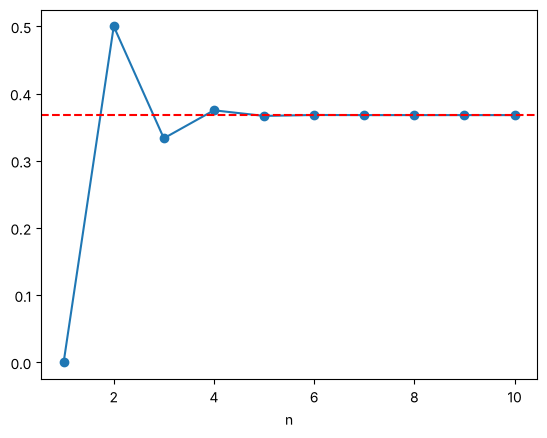

In [13]:
from sympy.functions.combinatorial.numbers import subfactorial
rows=[(nn,int(subfactorial(nn)),int(sp.factorial(nn)),int(subfactorial(nn))/int(sp.factorial(nn))) for nn in range(1,11)]
for r in rows: print(f"n={r[0]:>2}  !n={r[1]:>8}  n!={r[2]:>8}  P={r[3]:.6f}")
print("1/e =",float(sp.exp(-1)))
# simulasi n=10
rng=np.random.default_rng(0); N=200_000
fix=np.array([(rng.permutation(10)==np.arange(10)).sum() for _ in range(N)])
print("sim P(0 titik tetap) =",(fix==0).mean().round(4)," | sim E[titik tetap] =",fix.mean().round(3))
ns=[r[0] for r in rows]; plt.plot(ns,[r[3] for r in rows],'o-'); plt.axhline(float(sp.exp(-1)),c='r',ls='--'); plt.xlabel("n"); plt.show()

**Interpretasi:** Peluang konvergen sangat cepat ke 1/e≈0,3679, hampir tidak bergantung pada n (sudah akurat untuk n≥7). E[titik tetap]=1 untuk semua n (linearitas harapan, meski indikator-indikatornya tidak independen). Simulasi dan hitungan eksak cocok.

## Kesimpulan
1. SymPy memberi **jawaban eksak** (pecahan/rumus) sehingga ideal untuk memverifikasi hitungan manual dan menurunkan rumus (Bayes umum, π stasioner, E dan Var, MGF).
2. `sympy.stats` menangani RV diskrit dan kontinu, termasuk probabilitas bersyarat via `P(A, B)`.
3. Keterbatasan: lambat untuk komputasi besar/simulasi dan integral yang tidak punya bentuk tertutup — di sana pakai NumPy/SciPy.